# Lab 1 – Introduction to Deep Learning (AI & Cybersecurity)
## Task 2 – Your First Network (2A, 2B, 2C)

Goal: design and train a minimal single-hidden-layer Feed-Forward Neural Network (FFNN) for 4-class intrusion detection on the Task 1 preprocessed dataset, diagnose how missing fundamentals (feature scaling and learning rate) break training, and lock in a well-understood baseline on validation before evaluating generalization on the held-out test set.

Notebook outline:
1. Setup, reproducibility, and loading Task 1 preprocessed data
2. Model architecture (`FFNN`), training loop with early stopping, and experiment logbook helper
3. Task 2A – Minimal working classifier (Run 1: prediction, training, loss curves, validation report, Q&A)
4. Task 2B – Why the fundamentals matter (Runs 2–4: S1 no scaling, S2 too-high LR, S3 too-low LR; predictions, curves, failure mechanisms, ranking & symptom-reading Q&A)
5. Task 2C – Lock in your baseline (Run 5: Linear vs ReLU controlled experiment; locking in Run 1 baseline; validation vs test generalization comparison & Q&A)
6. Experiment Logbook (Runs 1–5) & artifact export
7. Consolidated answers to all Task 2 questions

## 1. Setup & Data Loading

We fix all random seeds (`SEED = 42`) and restrict PyTorch to a single CPU thread (`torch.set_num_threads(1)`) for deterministic and fast execution on small feed-forward layers. We load the exact Task 1 partitions from `task1_outputs/task1_preprocessed_with_port.npz`, with an inline fallback that reproduces the exact Task 1 `preprocess()` pipeline from `dataset_lab_1.csv` if the `.npz` cache is absent.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

OUT_DIR = "task2_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
NPZ_PATH = "task1_outputs/task1_preprocessed_with_port.npz"
CSV_PATH = "dataset_lab_1.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load_task1_data(npz_path=NPZ_PATH, csv_path=CSV_PATH, seed=SEED):
    if os.path.exists(npz_path):
        d = np.load(npz_path, allow_pickle=False)
        return {k: d[k] for k in d.files}
    assert os.path.exists(csv_path), f"Neither {npz_path} nor {csv_path} found."
    df = pd.read_csv(csv_path)
    label_col = "Label"
    feats = [c for c in df.columns if c != label_col]
    df[feats] = df[feats].replace([np.inf, -np.inf], np.nan)
    df = df.dropna()
    df = df[~(df[feats] < 0).any(axis=1)].drop_duplicates().reset_index(drop=True)
    classes = sorted(df[label_col].unique())
    cls2id = {c: i for i, c in enumerate(classes)}
    y = df[label_col].map(cls2id).values
    i_tr, i_tmp = train_test_split(np.arange(len(df)), test_size=0.30, random_state=seed, stratify=y)
    i_va, i_te = train_test_split(i_tmp, test_size=0.50, random_state=seed, stratify=y[i_tmp])
    log_feats = [c for c in feats if c not in {"Fwd PSH Flags", "SYN Flag Count", "Down/Up Ratio", "Destination Port"}]
    def tf(ix):
        x = df.loc[ix, feats].copy()
        x[log_feats] = np.log1p(x[log_feats])
        return x
    X_tr_tf, X_va_tf, X_te_tf = tf(i_tr), tf(i_va), tf(i_te)
    scaler = StandardScaler().fit(X_tr_tf)
    return {
        "X_train": scaler.transform(X_tr_tf).astype("float32"), "y_train": y[i_tr],
        "X_val": scaler.transform(X_va_tf).astype("float32"), "y_val": y[i_va],
        "X_test": scaler.transform(X_te_tf).astype("float32"), "y_test": y[i_te],
        "X_train_raw": df.loc[i_tr, feats].to_numpy(dtype="float32"),
        "X_val_raw": df.loc[i_va, feats].to_numpy(dtype="float32"),
        "X_test_raw": df.loc[i_te, feats].to_numpy(dtype="float32"),
        "features": np.array(feats), "log_features": np.array(log_feats), "classes": np.array(classes),
    }

data = load_task1_data()
X_tr, y_tr = data["X_train"], data["y_train"]
X_va, y_va = data["X_val"], data["y_val"]
X_te, y_te = data["X_test"], data["y_test"]
X_tr_raw, X_va_raw, X_te_raw = data["X_train_raw"], data["X_val_raw"], data["X_test_raw"]
FEATURES = data["features"].tolist()
CLASSES = data["classes"].tolist()

print(f"Loaded features ({len(FEATURES)}): {FEATURES}")
print(f"Classes ({len(CLASSES)}): {CLASSES}")
print(f"Shapes | train: {X_tr.shape}  val: {X_va.shape}  test: {X_te.shape}")
split_counts = pd.DataFrame({
    "train": pd.Series(y_tr).value_counts().sort_index(),
    "val": pd.Series(y_va).value_counts().sort_index(),
    "test": pd.Series(y_te).value_counts().sort_index(),
})
split_counts.index = [CLASSES[i] for i in split_counts.index]
split_counts.loc["TOTAL"] = split_counts.sum()
display(split_counts)

Loaded features (16): ['Flow Duration', 'Flow IAT Mean', 'Fwd PSH Flags', 'Bwd Packet Length Mean', 'Bwd Packet Length Max', 'Flow Bytes/s', 'Down/Up Ratio', 'SYN Flag Count', 'Fwd Packet Length Mean', 'Fwd IAT Std', 'Packet Length Mean', 'Fwd Packet Length Max', 'Subflow Fwd Packets', 'Flow Packets/s', 'Total Fwd Packets', 'Destination Port']
Classes (4): ['Benign', 'Brute Force', 'DoS Hulk', 'PortScan']
Shapes | train: (20568, 16)  val: (4408, 16)  test: (4408, 16)


,train,val,test
Benign,13467,2886,2887
Brute Force,999,214,214
DoS Hulk,2708,580,580
PortScan,3394,728,727
TOTAL,20568,4408,4408


## 2. Architecture, Training Loop & Experiment Logbook Helper

Every Task 2A baseline choice is stated explicitly before running:
- **Architecture (`FFNN`):** single hidden layer with `64` units (`16 → 64 → 4`, `1,348` trainable parameters) and `ReLU` activation (`nn.ReLU()`, swapped to `nn.Identity()` in Task 2C's controlled linear experiment).
- **Loss function:** unweighted `nn.CrossEntropyLoss()` (class-weighted loss is deferred to Task 4).
- **Optimizer:** `torch.optim.AdamW` with learning rate `lr = 5e-4` and `weight_decay = 0.0` (regularization is deferred to Task 5).
- **Batching & reproducibility:** `batch_size = 64`, shuffled each epoch with `torch.randperm(n, generator=gen)` seeded at `SEED = 42`.
- **Stopping criterion & checkpoint selection:** train for up to `max_epochs = 100` with early stopping on **validation cross-entropy loss** (`patience = 12`, `min_delta = 1e-4`). Whenever `val_loss < best_val_loss - min_delta`, we snapshot `model.state_dict()` and record `best_epoch`. At the end of training, we restore `best_state` so all validation metrics reflect the checkpoint with the lowest validation loss.

In [2]:
class FFNN(nn.Module):
    def __init__(self, in_dim=16, hidden=64, out_dim=4, activation="relu"):
        super().__init__()
        if activation == "relu":
            act = nn.ReLU()
        elif activation == "linear":
            act = nn.Identity()
        else:
            raise ValueError(f"Unsupported activation: {activation}")
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            act,
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)


def train_model(
    X_train, y_train, X_val, y_val,
    lr=5e-4, hidden=64, activation="relu",
    batch_size=64, max_epochs=100, patience=12, min_delta=1e-4, seed=SEED,
):
    np.random.seed(seed)
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)

    X_tr_t = torch.from_numpy(X_train)
    y_tr_t = torch.from_numpy(y_train).long()
    X_va_t = torch.from_numpy(X_val)
    y_va_t = torch.from_numpy(y_val).long()
    n = len(X_tr_t)

    model = FFNN(X_train.shape[1], hidden, len(CLASSES), activation=activation)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    wait = 0
    tr_losses, va_losses, va_accs, va_f1s = [], [], [], []

    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        X_shuf, y_shuf = X_tr_t[perm], y_tr_t[perm]
        running_loss = 0.0
        for i in range(0, n, batch_size):
            xb, yb = X_shuf[i : i + batch_size], y_shuf[i : i + batch_size]
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(yb)
        tr_loss = running_loss / n

        model.eval()
        with torch.no_grad():
            va_logits = model(X_va_t)
            va_loss = criterion(va_logits, y_va_t).item()
            va_pred = va_logits.argmax(dim=1).numpy()
            va_acc = accuracy_score(y_val, va_pred)
            va_f1 = f1_score(y_val, va_pred, average="macro")

        tr_losses.append(tr_loss)
        va_losses.append(va_loss)
        va_accs.append(va_acc)
        va_f1s.append(va_f1)

        if np.isnan(va_loss) or np.isinf(va_loss):
            break

        if va_loss < best_val_loss - min_delta:
            best_val_loss = va_loss
            best_epoch = epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if patience is not None and wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    with torch.no_grad():
        final_logits = model(X_va_t)
        final_val_loss = criterion(final_logits, y_va_t).item()
        va_preds = final_logits.argmax(dim=1).numpy()

    _, _, per_cls_f1, _ = precision_recall_fscore_support(y_val, va_preds, labels=range(len(CLASSES)), zero_division=0)
    return {
        "model": model,
        "tr_losses": tr_losses,
        "va_losses": va_losses,
        "va_accs": va_accs,
        "va_f1s": va_f1s,
        "best_epoch": best_epoch,
        "stopped_epoch": len(tr_losses),
        "best_val_loss": final_val_loss,
        "final_val_loss": va_losses[-1],
        "val_acc": accuracy_score(y_val, va_preds),
        "val_macro_f1": f1_score(y_val, va_preds, average="macro"),
        "val_preds": va_preds,
        "per_class_f1": {c: float(per_cls_f1[i]) for i, c in enumerate(CLASSES)},
    }


def evaluate_split(model, X, y):
    model.eval()
    X_t = torch.from_numpy(X)
    y_t = torch.from_numpy(y).long()
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        logits = model(X_t)
        loss = criterion(logits, y_t).item()
        preds = logits.argmax(dim=1).numpy()
    _, _, per_cls_f1, _ = precision_recall_fscore_support(y, preds, labels=range(len(CLASSES)), zero_division=0)
    return {
        "loss": loss,
        "acc": accuracy_score(y, preds),
        "macro_f1": f1_score(y, preds, average="macro"),
        "preds": preds,
        "per_class_f1": {c: float(per_cls_f1[i]) for i, c in enumerate(CLASSES)},
    }


LOGBOOK = []

def log_run(run_id, task, changed, budget_why, hypothesis, key_result, concluded):
    LOGBOOK.append({
        "Run": run_id,
        "Task": task,
        "What I changed (one thing)": changed,
        "Budget justification": budget_why,
        "Hypothesis before running": hypothesis,
        "Key result (val)": key_result,
        "What I concluded": concluded,
    })

n_params = sum(p.numel() for p in FFNN(len(FEATURES), 64, len(CLASSES)).parameters())
print(f"FFNN(16 -> 64 -> 4) trainable parameters: {n_params:,}")

FFNN(16 -> 64 -> 4) trainable parameters: 1,348


## 3. Task 2A – Build a Minimal Working Classifier

### Predict first (before Run 1)
Connecting directly to our **Task 1** measurements:
1. **`Brute Force` (4.86%, 999 train / 214 val flows)** is predicted to be the **hardest class** because it has ~13.5× fewer training samples than `Benign` (under unweighted cross-entropy loss, gradient contributions scale with class frequency) and 100% of its flows use `Destination Port = 80`, colliding with `DoS Hulk` (`2,708` train flows, also 100% on port 80) and HTTP `Benign` traffic.
2. **`DoS Hulk` (13.17%, 2,708 train / 580 val flows)** is predicted to be the **second hardest**: it sits entirely on port 80, lost 22.6% of its raw rows during deduplication, and shares the 7 exact feature-identical conflicting-label pairs with `Benign`.
3. **`PortScan` (16.50%, 3,394 train / 728 val flows)** and **`Benign` (65.48%)** are predicted to be the **easiest classes** (`PortScan` exhibits distinctive short-probe patterns across 995 ports; `Benign` dominates the training loss).

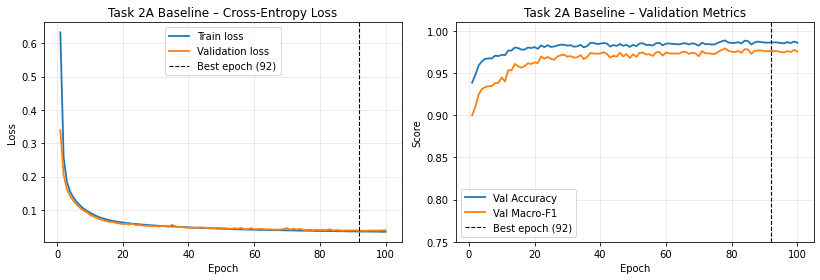

Run 1 (2A Baseline) | stopped_epoch=100  best_epoch=92  best_val_loss=0.0377  val_acc=0.9864  val_macro_f1=0.9759
Train loss: epoch 1 = 0.6328 -> final = 0.0347
Val loss  : epoch 1 = 0.3394 -> best = 0.0377 (final = 0.0392)

Validation classification report:
              precision    recall  f1-score   support

      Benign     0.9883    0.9917    0.9900      2886
 Brute Force     0.9025    0.9953    0.9467       214
    DoS Hulk     0.9946    0.9448    0.9691       580
    PortScan     1.0000    0.9959    0.9979       728

    accuracy                         0.9864      4408
   macro avg     0.9713    0.9819    0.9759      4408
weighted avg     0.9869    0.9864    0.9864      4408



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2862,23,1,0
True: Brute Force,1,213,0,0
True: DoS Hulk,32,0,548,0
True: PortScan,1,0,2,725


In [3]:
run1 = train_model(X_tr, y_tr, X_va, y_va, lr=5e-4, hidden=64, activation="relu", batch_size=64, max_epochs=100, patience=12)

log_run(
    run_id=1,
    task="2A",
    changed="Baseline: 1x64 ReLU, lr=5e-4, AdamW, bs=64, scaled features",
    budget_why="Slot 1/25: establish minimal working 2A baseline",
    hypothesis="Brute Force hardest (4.86% rare + port-80 overlap with DoS Hulk/Benign); PortScan & Benign easiest",
    key_result=(
        f"best_ep={run1['best_epoch']}/{run1['stopped_epoch']}, val_loss={run1['best_val_loss']:.4f}, "
        f"acc={run1['val_acc']:.4f}, macro-F1={run1['val_macro_f1']:.4f}, "
        f"BF F1={run1['per_class_f1']['Brute Force']:.4f}"
    ),
    concluded="Converges smoothly; F1 ranking holds (BF lowest at 0.9467), with BF recall 0.9953 (precision 0.9025) aided by port 80.",
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
ep = np.arange(1, len(run1["tr_losses"]) + 1)
axes[0].plot(ep, run1["tr_losses"], label="Train loss", lw=1.8)
axes[0].plot(ep, run1["va_losses"], label="Validation loss", lw=1.8)
axes[0].axvline(run1["best_epoch"], color="k", ls="--", lw=1.1, label=f"Best epoch ({run1['best_epoch']})")
axes[0].set_title("Task 2A Baseline – Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(ep, run1["va_accs"], label="Val Accuracy", lw=1.8)
axes[1].plot(ep, run1["va_f1s"], label="Val Macro-F1", lw=1.8)
axes[1].axvline(run1["best_epoch"], color="k", ls="--", lw=1.1, label=f"Best epoch ({run1['best_epoch']})")
axes[1].set_title("Task 2A Baseline – Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.75, 1.01)
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task2a_baseline_curves.png")
plt.show()

print(
    f"Run 1 (2A Baseline) | stopped_epoch={run1['stopped_epoch']}  best_epoch={run1['best_epoch']}  "
    f"best_val_loss={run1['best_val_loss']:.4f}  val_acc={run1['val_acc']:.4f}  val_macro_f1={run1['val_macro_f1']:.4f}"
)
print(f"Train loss: epoch 1 = {run1['tr_losses'][0]:.4f} -> final = {run1['tr_losses'][-1]:.4f}")
print(f"Val loss  : epoch 1 = {run1['va_losses'][0]:.4f} -> best = {run1['best_val_loss']:.4f} (final = {run1['final_val_loss']:.4f})\n")
print("Validation classification report:")
print(classification_report(y_va, run1["val_preds"], target_names=CLASSES, digits=4))

cm_2a = pd.DataFrame(
    confusion_matrix(y_va, run1["val_preds"]),
    index=[f"True: {c}" for c in CLASSES],
    columns=[f"Pred: {c}" for c in CLASSES],
)
display(cm_2a)

### Reconcile & Task 2A Questions

- **Q: How do you pick the "best" model across epochs? Do the curves converge?**
  We select the checkpoint with the **lowest validation cross-entropy loss** (`best_epoch = 92`, `best_val_loss = 0.0377`). Validation cross-entropy is preferred over discrete accuracy or macro-F1 for checkpointing because it is smooth and sensitive to probability calibration rather than hard thresholding, which helps prevent choosing an overconfident, overfitting epoch. Both curves converge cleanly with no divergence: training loss drops smoothly from `0.6328` to `0.0347` and validation loss drops from `0.3394` to `0.0377` (`0.0392` at epoch 100), leaving a minimal train-validation gap (`~0.003`).
- **Q: Do your hardest-class predictions hold up? Explain the per-class results.**
  Yes in terms of F1 ranking: `PortScan` (`0.9979`) > `Benign` (`0.9900`) > `DoS Hulk` (`0.9691`) > `Brute Force` (`0.9467`). Inspecting precision vs. recall reveals an important nuance: `Brute Force` actually achieves **`0.9953` recall** (detecting `213 / 214` validation attacks) and suffers primarily on **precision (`0.9025`)** due to `23` `Benign` flows misclassified as `Brute Force` on port 80, while `DoS Hulk` has high precision (`0.9946`) but slightly lower recall (`0.9448`, with `32` flows predicted as `Benign`). Because 100% of `Brute Force` flows sit on `Destination Port = 80`, the network uses port 80 as a high-recall shortcut—something we will test directly in Task 3.

## 4. Task 2B – Why the Fundamentals Matter

We take the exact Task 2A setup (`1×64 ReLU`, `AdamW`, `bs = 64`, `patience = 12`) and break **one fundamental at a time**:
- **S1 – No feature scaling (`Run 2`):** raw unscaled features `X_train_raw` / `X_val_raw` (`lr = 5e-4`).
  *Prediction:* Because raw features span `0` to `2.07×10⁹` (`Flow Bytes/s`) and `1.2×10⁸` (`Flow Duration`), initial random linear weights (`~1/√16`) produce huge hidden activations and logits (`10³–10⁸`), starting cross-entropy loss at `10³–10⁴+`, causing extreme gradient anisotropy across coordinates and erratic, non-converging loss oscillations that trigger early stopping well before reaching a well-calibrated solution.
- **S2 – Far too high learning rate (`Run 3`):** `lr = 0.5` (`1,000×` baseline) on scaled features.
  *Prediction:* Expected breakdown threshold for `AdamW` on standardized inputs is around `lr > 1e-2`, and by `lr = 0.5` parameter updates (`±0.5`) exceed typical initial weight magnitudes (`~0.25`). We expect an initial brief drop over 1–3 epochs followed by violent overshooting, climbing validation loss, dead ReLUs pushed permanently into the negative half-plane, and collapse on the rarest class (`Brute Force`).
- **S3 – Learning rate far too low (`Run 4`):** `lr = 5e-6` (`100×` smaller than baseline) on scaled features.
  *Prediction:* Training will be completely stable and monotonic with virtually zero noise, but progress will be ~100× too slow: early stopping will never fire within `100` epochs, and validation loss will end around `~0.30` (comparable to epoch 1–2 of the baseline), underfitting harder classes (`Brute Force`, `DoS Hulk`).

In [4]:
run2_s1 = train_model(X_tr_raw, y_tr, X_va_raw, y_va, lr=5e-4, hidden=64, activation="relu", batch_size=64, max_epochs=100, patience=12)
log_run(
    run_id=2,
    task="2B",
    changed="S1: raw unscaled features (lr=5e-4)",
    budget_why="Slot 2/25: Task 2B S1 missing feature scaling failure mode",
    hypothesis="Huge input scale (up to 2e9) inflates logits/loss to 1e3-1e4+, causing erratic oscillations & early stop",
    key_result=(
        f"stopped={run2_s1['stopped_epoch']} (best_ep={run2_s1['best_epoch']}), "
        f"best_val_loss={run2_s1['best_val_loss']:.2f} (final={run2_s1['final_val_loss']:.2f}), "
        f"acc={run2_s1['val_acc']:.4f}, macro-F1={run2_s1['val_macro_f1']:.4f}"
    ),
    concluded="Confirmed: ill-conditioned raw features explode loss to ~7.6e4 init / 777+ val; macro-F1 drops to 0.9017.",
)

run3_s2 = train_model(X_tr, y_tr, X_va, y_va, lr=0.5, hidden=64, activation="relu", batch_size=64, max_epochs=100, patience=12)
log_run(
    run_id=3,
    task="2B",
    changed="S2: lr 5e-4 -> 0.5 (1000x higher)",
    budget_why="Slot 3/25: Task 2B S2 excessive learning rate failure mode",
    hypothesis="Step size ~0.5 overshoots valley walls, causing rising val loss, dead ReLUs, and Brute Force collapse",
    key_result=(
        f"stopped={run3_s2['stopped_epoch']} (best_ep={run3_s2['best_epoch']}), "
        f"best_val_loss={run3_s2['best_val_loss']:.4f} (final={run3_s2['final_val_loss']:.4f}), "
        f"acc={run3_s2['val_acc']:.4f}, macro-F1={run3_s2['val_macro_f1']:.4f}, BF F1={run3_s2['per_class_f1']['Brute Force']:.4f}"
    ),
    concluded="Confirmed: val loss diverges after ep 2; Brute Force collapses completely to 0.0000 recall/F1 (macro-F1=0.7165).",
)

run4_s3 = train_model(X_tr, y_tr, X_va, y_va, lr=5e-6, hidden=64, activation="relu", batch_size=64, max_epochs=100, patience=12)
log_run(
    run_id=4,
    task="2B",
    changed="S3: lr 5e-4 -> 5e-6 (100x smaller)",
    budget_why="Slot 4/25: Task 2B S3 overly small learning rate failure mode",
    hypothesis="Smooth monotonic descent without early stopping, stalling near loss ~0.30 at epoch 100 (underfitting)",
    key_result=(
        f"stopped={run4_s3['stopped_epoch']} (best_ep={run4_s3['best_epoch']}), "
        f"best_val_loss={run4_s3['best_val_loss']:.4f}, acc={run4_s3['val_acc']:.4f}, macro-F1={run4_s3['val_macro_f1']:.4f}"
    ),
    concluded="Confirmed: smooth slow underfitting (1.33 -> 0.2989 at ep 100); DoS Hulk recall=0.7724, BF F1=0.8174.",
)

s_rows = []
for label, r in [
    ("2A Baseline (scaled, lr=5e-4)", run1),
    ("2B-S1 No scaling (raw, lr=5e-4)", run2_s1),
    ("2B-S2 High LR (scaled, lr=0.5)", run3_s2),
    ("2B-S3 Low LR (scaled, lr=5e-6)", run4_s3),
]:
    s_rows.append({
        "Setup": label,
        "Stopped ep": r["stopped_epoch"],
        "Best ep": r["best_epoch"],
        "Init train loss": round(r["tr_losses"][0], 4),
        "Best val loss": round(r["best_val_loss"], 4),
        "Final val loss": round(r["final_val_loss"], 4),
        "Val Acc": round(r["val_acc"], 4),
        "Val Macro-F1": round(r["val_macro_f1"], 4),
        "BF F1": round(r["per_class_f1"]["Brute Force"], 4),
        "DoS Hulk F1": round(r["per_class_f1"]["DoS Hulk"], 4),
    })
display(pd.DataFrame(s_rows).set_index("Setup"))

for title, r in [("S1 (No scaling)", run2_s1), ("S2 (High LR = 0.5)", run3_s2), ("S3 (Low LR = 5e-6)", run4_s3)]:
    print(f"=== Validation Classification Report: {title} ===")
    print(classification_report(y_va, r["val_preds"], target_names=CLASSES, digits=4, zero_division=0))

,Stopped ep,Best ep,Init train loss,Best val loss,Final val loss,Val Acc,Val Macro-F1,BF F1,DoS Hulk F1
Setup,,,,,,,,,
"2A Baseline (scaled, lr=5e-4)",100,92,0.6328,0.0377,0.0392,0.9864,0.9759,0.9467,0.9691
"2B-S1 No scaling (raw, lr=5e-4)",50,38,76013.0525,777.3787,2562.7195,0.9403,0.9017,0.8070,0.8676
"2B-S2 High LR (scaled, lr=0.5)",14,2,1.4417,0.2005,0.6619,0.9308,0.7165,0.0000,0.9185
"2B-S3 Low LR (scaled, lr=5e-6)",100,100,1.3273,0.2989,0.2989,0.9381,0.8979,0.8174,0.8574


=== Validation Classification Report: S1 (No scaling) ===
              precision    recall  f1-score   support

      Benign     0.9688    0.9453    0.9569      2886
 Brute Force     0.7603    0.8598    0.8070       214
    DoS Hulk     0.8596    0.8759    0.8676       580
    PortScan     0.9552    0.9959    0.9751       728

    accuracy                         0.9403      4408
   macro avg     0.8860    0.9192    0.9017      4408
weighted avg     0.9420    0.9403    0.9409      4408

=== Validation Classification Report: S2 (High LR = 0.5) ===
              precision    recall  f1-score   support

      Benign     0.9054    0.9986    0.9497      2886
 Brute Force     0.0000    0.0000    0.0000       214
    DoS Hulk     0.9920    0.8552    0.9185       580
    PortScan     1.0000    0.9959    0.9979       728

    accuracy                         0.9308      4408
   macro avg     0.7244    0.7124    0.7165      4408
weighted avg     0.8885    0.9308    0.9075      4408

=== Validat

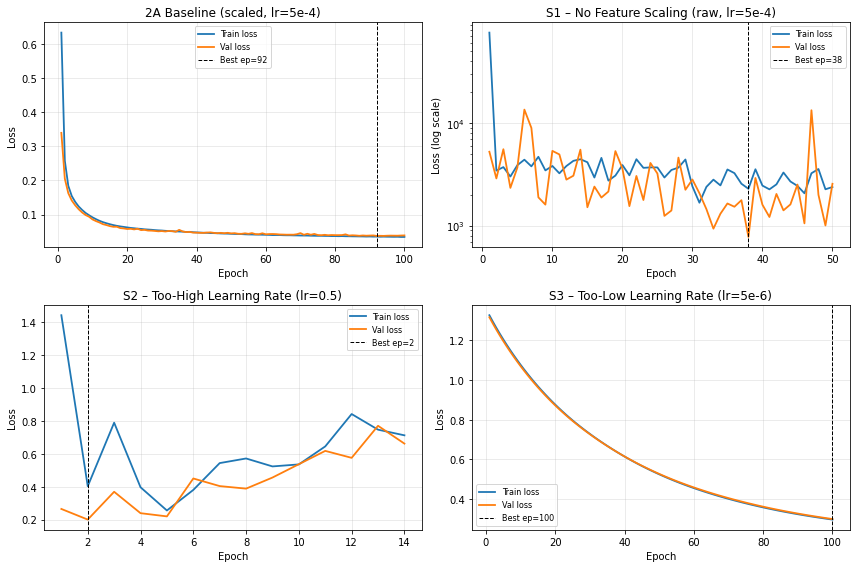

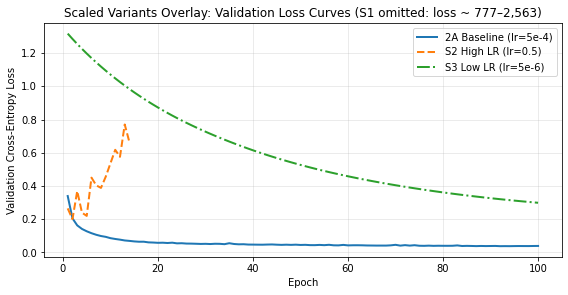

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12.0, 8.0))
panels = [
    (axes[0, 0], run1, "2A Baseline (scaled, lr=5e-4)", False),
    (axes[0, 1], run2_s1, "S1 – No Feature Scaling (raw, lr=5e-4)", True),
    (axes[1, 0], run3_s2, "S2 – Too-High Learning Rate (lr=0.5)", False),
    (axes[1, 1], run4_s3, "S3 – Too-Low Learning Rate (lr=5e-6)", False),
]
for ax, r, title, use_log in panels:
    ep = np.arange(1, len(r["tr_losses"]) + 1)
    ax.plot(ep, r["tr_losses"], label="Train loss", lw=1.8)
    ax.plot(ep, r["va_losses"], label="Val loss", lw=1.8)
    ax.axvline(r["best_epoch"], color="k", ls="--", lw=1.0, label=f"Best ep={r['best_epoch']}")
    if use_log:
        ax.set_yscale("log")
        ax.set_ylabel("Loss (log scale)")
    else:
        ax.set_ylabel("Loss")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task2b_failure_modes.png")
plt.show()

fig, ax = plt.subplots(figsize=(8.0, 4.2))
for name, r, style in [
    ("2A Baseline (lr=5e-4)", run1, "-"),
    ("S2 High LR (lr=0.5)", run3_s2, "--"),
    ("S3 Low LR (lr=5e-6)", run4_s3, "-."),
]:
    ep = np.arange(1, len(r["va_losses"]) + 1)
    ax.plot(ep, r["va_losses"], ls=style, lw=2.0, label=name)
ax.set_title("Scaled Variants Overlay: Validation Loss Curves (S1 omitted: loss ~ 777–2,563)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Cross-Entropy Loss")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task2b_overlay_scaled.png")
plt.show()

### Task 2B – Failure Mode Analysis & Questions

- **Named failure modes & mechanisms:**
  1. **S1 (No scaling) — Exploding logit scale & severe gradient anisotropy:** Because `Flow Bytes/s` reaches `~2.07×10⁹` and `Flow Duration` reaches `~1.2×10⁸` while binary flags sit in `{0, 1}`, initial dot products blow up logits by 4–5 orders of magnitude: epoch-1 train loss is `76,013.05`, best validation loss is `777.38` (epoch 38), and validation loss rebounds erratically to `2,562.72` at epoch 50 (`macro-F1 = 0.9017`, `Brute Force` F1 `0.8070`, `DoS Hulk` F1 `0.8676`). Even though AdamW normalizes per-parameter step sizes over time, raw feature magnitudes dominate linear combinations and destroy probability calibration and boundary refinement.
  2. **S2 (`lr = 0.5`) — Optimization overshooting, divergence & dead-ReLU minority collapse:** With updates comparable to the weights themselves, validation loss dips briefly to `0.2005` at epoch 2 and then diverges upward to `0.6619` by epoch 14. Crucially, even at the best checkpoint (`epoch 2`), **every single `Brute Force` sample is missed (`recall = 0.0000`, `F1 = 0.0000`)**, slashing `macro-F1` to **`0.7165`** while overall accuracy (`0.9308`) dangerously masks the total failure on the rarest attack class.
  3. **S3 (`lr = 5e-6`) — Stalled optimization / severe underfitting:** Validation loss decreases smoothly and noiselessly from `1.3273` (train init) to `0.2989` at epoch 100 (`best_epoch = 100`, early stopping never triggers), reaching only `macro-F1 = 0.8979` (`DoS Hulk` recall `0.7724`, `Brute Force` F1 `0.8174`) because parameter updates are 100× too small to traverse the loss landscape within 100 epochs.

- **Q: Rank S1–S3 by how badly they hurt, and say which fundamental — scaling or the learning rate — you would get right first on a new problem.**
  - *Ranking by intrusion-detection utility (`macro-F1` and rare-attack detection):* **S2 (`lr=0.5`, `macro-F1 = 0.7165`, `Brute Force` F1 `0.0000`) hurts worst** > **S3 (`lr=5e-6`, `macro-F1 = 0.8979`, `Brute Force` F1 `0.8174`)** ≈ **S1 (no scaling, `macro-F1 = 0.9017`, `Brute Force` F1 `0.8070`)**, with S1 suffering worse on `Brute Force` and severe loss pathology while S3 merely stops short of convergence.
  - *Ranking by numerical loss pathology:* **S1 (`best_val_loss = 777.38`, `init_train_loss = 76,013`)** is by far the most broken numerically because unscaled inputs drive logits to extreme scales.
  - *Which fundamental to get right first:* **Feature scaling first, then learning rate.** Gradient magnitudes scale linearly with feature magnitudes (`∂L/∂W = δ · xᵀ`), so features spanning 9 orders of magnitude create an ill-conditioned loss surface where *no* single scalar learning rate works well across all coordinates. Once inputs are standardized (`mean ≈ 0, std ≈ 1`), standard learning rates (`3e-4`–`1e-3` for AdamW) work reliably out of the box.

- **Q (reading symptoms): What in the shape of an unlabelled loss curve points to each cause?**
  - **Loss magnitude `10³–10⁵+` at epoch 1 with erratic multi-hundred/thousand spikes:** **Unscaled features (S1)** — raw input magnitudes directly inflate initial logits and cross-entropy by orders of magnitude.
  - **Normal `O(1)` start, rapid initial drop for 1–3 epochs followed by sharp upward bounce, noisy jagged oscillations, and early stopping:** **Too-high learning rate (S2)** — step size overshoots minima and bounces across steep valley walls.
  - **Normal `O(1)` start followed by a smooth, nearly noise-free, slow downward slope still clearly decreasing at the final epoch without plateauing:** **Too-low learning rate (S3)** — stable direction, insufficient step size.

## 5. Task 2C – Lock In Your Baseline

### Controlled experiment: ReLU vs. Linear activation (predict first, before Run 5)
Replacing `ReLU` with `Linear` (`nn.Identity()`) reduces the 2-layer network `W₂(W₁x + b₁) + b₂` to a single affine classifier `W_eff x + b_eff` (equivalent to multinomial logistic regression).
- *Prediction:* Classes that are largely linearly separable in log-scaled feature space (`PortScan`, `Benign`) should maintain high F1, whereas classes that overlap on `Destination Port = 80` (`Brute Force`, `DoS Hulk`) and require non-linear feature interactions should degrade substantially.
- **Methodology rule:** We compare `ReLU` (Run 1) vs. `Linear` (Run 5) strictly on the **validation set**. Only after locking in our chosen baseline do we evaluate it once on the held-out **test set**.

,ReLU (Run 1),Linear (Run 5),Delta (Linear - ReLU)
Val Loss,0.0377,0.1419,0.1042
Val Accuracy,0.9864,0.9580,-0.0284
Val Macro-F1,0.9759,0.9152,-0.0607
F1: Benign,0.9900,0.9729,-0.0171
F1: Brute Force,0.9467,0.7885,-0.1581
F1: DoS Hulk,0.9691,0.9056,-0.0634
F1: PortScan,0.9979,0.9938,-0.0041


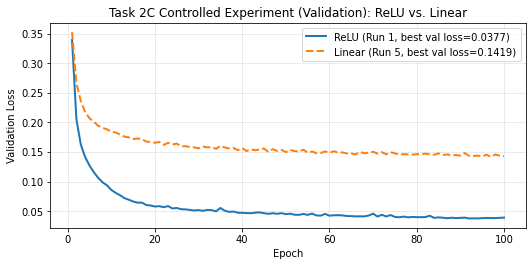

Validation classification report – Linear (Run 5):
              precision    recall  f1-score   support

      Benign     0.9766    0.9692    0.9729      2886
 Brute Force     0.7458    0.8364    0.7885       214
    DoS Hulk     0.9096    0.9017    0.9056       580
    PortScan     0.9931    0.9945    0.9938       728

    accuracy                         0.9580      4408
   macro avg     0.9063    0.9255    0.9152      4408
weighted avg     0.9593    0.9580    0.9585      4408



In [6]:
run5_lin = train_model(X_tr, y_tr, X_va, y_va, lr=5e-4, hidden=64, activation="linear", batch_size=64, max_epochs=100, patience=12)

log_run(
    run_id=5,
    task="2C",
    changed="Activation ReLU -> Linear (nn.Identity)",
    budget_why="Slot 5/25: controlled Task 2C ablation (non-linearity vs linear classifier)",
    hypothesis="Collapsing hidden ReLU to linear map hurts port-80 overlapping classes (Brute Force, DoS Hulk) far more than PortScan",
    key_result=(
        f"best_ep={run5_lin['best_epoch']}/{run5_lin['stopped_epoch']}, val_loss={run5_lin['best_val_loss']:.4f}, "
        f"acc={run5_lin['val_acc']:.4f}, macro-F1={run5_lin['val_macro_f1']:.4f}, BF F1={run5_lin['per_class_f1']['Brute Force']:.4f}"
    ),
    concluded="Confirmed: PortScan barely moves (0.9979 -> 0.9938), while BF drops 15.8 pts (0.9467 -> 0.7885) and DoS Hulk 6.3 pts. Lock in Run 1 (ReLU).",
)

cmp_2c = pd.DataFrame({
    "ReLU (Run 1)": [
        run1["best_val_loss"], run1["val_acc"], run1["val_macro_f1"],
        run1["per_class_f1"]["Benign"], run1["per_class_f1"]["Brute Force"],
        run1["per_class_f1"]["DoS Hulk"], run1["per_class_f1"]["PortScan"],
    ],
    "Linear (Run 5)": [
        run5_lin["best_val_loss"], run5_lin["val_acc"], run5_lin["val_macro_f1"],
        run5_lin["per_class_f1"]["Benign"], run5_lin["per_class_f1"]["Brute Force"],
        run5_lin["per_class_f1"]["DoS Hulk"], run5_lin["per_class_f1"]["PortScan"],
    ],
}, index=["Val Loss", "Val Accuracy", "Val Macro-F1", "F1: Benign", "F1: Brute Force", "F1: DoS Hulk", "F1: PortScan"])
cmp_2c["Delta (Linear - ReLU)"] = cmp_2c["Linear (Run 5)"] - cmp_2c["ReLU (Run 1)"]
display(cmp_2c.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(np.arange(1, len(run1["va_losses"]) + 1), run1["va_losses"], label=f"ReLU (Run 1, best val loss={run1['best_val_loss']:.4f})", lw=2.0)
ax.plot(np.arange(1, len(run5_lin["va_losses"]) + 1), run5_lin["va_losses"], label=f"Linear (Run 5, best val loss={run5_lin['best_val_loss']:.4f})", lw=2.0, ls="--")
ax.set_title("Task 2C Controlled Experiment (Validation): ReLU vs. Linear")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Loss")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_task2c_relu_vs_linear.png")
plt.show()

print("Validation classification report – Linear (Run 5):")
print(classification_report(y_va, run5_lin["val_preds"], target_names=CLASSES, digits=4))

In [7]:
# Lock in Run 1 (1x64 ReLU) as the Task 2C baseline and evaluate ONCE on the held-out Test set
baseline_model = run1["model"]
torch.save({
    "model_state_dict": baseline_model.state_dict(),
    "in_dim": len(FEATURES),
    "hidden": 64,
    "out_dim": len(CLASSES),
    "activation": "relu",
    "features": FEATURES,
    "classes": CLASSES,
    "best_epoch": run1["best_epoch"],
    "best_val_loss": run1["best_val_loss"],
}, f"{OUT_DIR}/task2c_baseline_relu.pt")

val_eval = evaluate_split(baseline_model, X_va, y_va)
test_eval = evaluate_split(baseline_model, X_te, y_te)

gen_tbl = pd.DataFrame({
    "Validation": [
        val_eval["loss"], val_eval["acc"], val_eval["macro_f1"],
        val_eval["per_class_f1"]["Benign"], val_eval["per_class_f1"]["Brute Force"],
        val_eval["per_class_f1"]["DoS Hulk"], val_eval["per_class_f1"]["PortScan"],
    ],
    "Test": [
        test_eval["loss"], test_eval["acc"], test_eval["macro_f1"],
        test_eval["per_class_f1"]["Benign"], test_eval["per_class_f1"]["Brute Force"],
        test_eval["per_class_f1"]["DoS Hulk"], test_eval["per_class_f1"]["PortScan"],
    ],
}, index=["Loss", "Accuracy", "Macro-F1", "F1: Benign", "F1: Brute Force", "F1: DoS Hulk", "F1: PortScan"])
gen_tbl["Gap (Test - Val)"] = gen_tbl["Test"] - gen_tbl["Validation"]
display(gen_tbl.round(4))

print("=== Locked-in Task 2C Baseline: VALIDATION Report ===")
print(classification_report(y_va, val_eval["preds"], target_names=CLASSES, digits=4))
print("=== Locked-in Task 2C Baseline: TEST Report ===")
print(classification_report(y_te, test_eval["preds"], target_names=CLASSES, digits=4))

cm_test = pd.DataFrame(
    confusion_matrix(y_te, test_eval["preds"]),
    index=[f"True: {c}" for c in CLASSES],
    columns=[f"Pred: {c}" for c in CLASSES],
)
display(cm_test)

,Validation,Test,Gap (Test - Val)
Loss,0.0377,0.0386,0.0008
Accuracy,0.9864,0.9853,-0.0011
Macro-F1,0.9759,0.9742,-0.0017
F1: Benign,0.9900,0.9891,-0.0009
F1: Brute Force,0.9467,0.9427,-0.0039
F1: DoS Hulk,0.9691,0.9683,-0.0007
F1: PortScan,0.9979,0.9966,-0.0014


=== Locked-in Task 2C Baseline: VALIDATION Report ===
              precision    recall  f1-score   support

      Benign     0.9883    0.9917    0.9900      2886
 Brute Force     0.9025    0.9953    0.9467       214
    DoS Hulk     0.9946    0.9448    0.9691       580
    PortScan     1.0000    0.9959    0.9979       728

    accuracy                         0.9864      4408
   macro avg     0.9713    0.9819    0.9759      4408
weighted avg     0.9869    0.9864    0.9864      4408

=== Locked-in Task 2C Baseline: TEST Report ===
              precision    recall  f1-score   support

      Benign     0.9889    0.9893    0.9891      2887
 Brute Force     0.8917    1.0000    0.9427       214
    DoS Hulk     0.9892    0.9483    0.9683       580
    PortScan     0.9986    0.9945    0.9966       727

    accuracy                         0.9853      4408
   macro avg     0.9671    0.9830    0.9742      4408
weighted avg     0.9858    0.9853    0.9853      4408



,Pred: Benign,Pred: Brute Force,Pred: DoS Hulk,Pred: PortScan
True: Benign,2856,25,5,1
True: Brute Force,0,214,0,0
True: DoS Hulk,29,1,550,0
True: PortScan,3,0,1,723


### Task 2C Questions

- **Q: Compare validation vs. test. Does it generalize (is the gap small)?**
  Yes—the generalization gap is negligible across every metric. On the locked-in `1×64 ReLU` baseline (`Run 1`), validation vs. test scores are:
  - Loss: `0.0377` vs. `0.0386` (`+0.0008`)
  - Accuracy: `0.9864` vs. `0.9853` (`-0.0011`)
  - Macro-F1: `0.9759` vs. `0.9742` (`-0.0017`)
  - Per-class F1 gaps: `Benign` `-0.0009` (`0.9900 → 0.9891`), `Brute Force` `-0.0039` (`0.9467 → 0.9427`, with `1.0000` test recall = `214/214`), `DoS Hulk` `-0.0007` (`0.9691 → 0.9683`), `PortScan` `-0.0014` (`0.9979 → 0.9966`).
  A sub-0.2% macro-F1 gap confirms strong out-of-sample generalization without overfitting to the validation split.
- **Q: Does switching the activation (Linear ↔ ReLU) change per-class behaviour? Would it be fair to compare these two on the test set, or is the test set off-limits for choosing between them? Why?**
  Switching from `ReLU` to `Linear` strongly changes per-class behavior: `PortScan` F1 barely moves (`0.9979 → 0.9938`, `-0.0041`) because port-scan flows are largely linearly separable, whereas **`Brute Force` F1 drops by `0.1581` (`0.9467 → 0.7885`)** and **`DoS Hulk` F1 drops by `0.0634` (`0.9691 → 0.9056`)** because separating port-80 attacks from port-80 benign flows requires non-linear combinations of duration, packet sizes, and rate features.
  **The test set is strictly off-limits for choosing between them.** Selecting the activation (or any hyperparameter/architecture) using test-set performance turns the test split into part of the model-selection loop, causing optimistic selection bias and invalidating the test set as an unbiased measure of generalization.

## 6. Experiment Logbook (Runs 1–5)

Tracking every training run with pre-run hypotheses, single-variable changes, validation outcomes, and budget usage (`5 / 25` runs used so far; `20` remaining for Tasks 3–5).

In [8]:
logbook_df = pd.DataFrame(LOGBOOK)
display(logbook_df)
logbook_df.to_csv(f"{OUT_DIR}/experiment_logbook_task2.csv", index=False)
print(f"Saved logbook ({len(logbook_df)}/25 runs spent) and baseline checkpoint to {OUT_DIR}/")

,Run,Task,What I changed (one thing),Budget justification,Hypothesis before running,Key result (val),What I concluded
0,1,2A,"Baseline: 1x64 ReLU, lr=5e-4, AdamW, bs=64, sc...",Slot 1/25: establish minimal working 2A baseline,Brute Force hardest (4.86% rare + port-80 over...,"best_ep=92/100, val_loss=0.0377, acc=0.9864, m...",Converges smoothly; F1 ranking holds (BF lowes...
1,2,2B,S1: raw unscaled features (lr=5e-4),Slot 2/25: Task 2B S1 missing feature scaling ...,Huge input scale (up to 2e9) inflates logits/l...,"stopped=50 (best_ep=38), best_val_loss=777.38 ...",Confirmed: ill-conditioned raw features explod...
2,3,2B,S2: lr 5e-4 -> 0.5 (1000x higher),Slot 3/25: Task 2B S2 excessive learning rate ...,"Step size ~0.5 overshoots valley walls, causin...","stopped=14 (best_ep=2), best_val_loss=0.2005 (...",Confirmed: val loss diverges after ep 2; Brute...
3,4,2B,S3: lr 5e-4 -> 5e-6 (100x smaller),Slot 4/25: Task 2B S3 overly small learning ra...,Smooth monotonic descent without early stoppin...,"stopped=100 (best_ep=100), best_val_loss=0.298...",Confirmed: smooth slow underfitting (1.33 -> 0...
4,5,2C,Activation ReLU -> Linear (nn.Identity),Slot 5/25: controlled Task 2C ablation (non-li...,Collapsing hidden ReLU to linear map hurts por...,"best_ep=97/100, val_loss=0.1419, acc=0.9580, m...",Confirmed: PortScan barely moves (0.9979 -> 0....


Saved logbook (5/25 runs spent) and baseline checkpoint to task2_outputs/


## 7. Consolidated Answers to Task 2 Questions

- **Task 2A – Model selection & convergence:** Best checkpoint selected at minimum validation cross-entropy loss (`best_epoch = 92`, `best_val_loss = 0.0377`). Both training (`0.6328 → 0.0347`) and validation (`0.3394 → 0.0392`) loss curves converge smoothly with a ~0.003 generalization gap.
- **Task 2A – Hardest-class prediction:** F1 ranking matched prediction (`PortScan` `0.9979` > `Benign` `0.9900` > `DoS Hulk` `0.9691` > `Brute Force` `0.9467`), with `Brute Force` attaining `0.9953` recall (`213/214`) but the lowest precision (`0.9025`) due to port-80 overlap with `Benign`.
- **Task 2B – Ranking S1–S3 & fundamental priority:** By macro-F1 / rare-class detection, **S2 (`lr=0.5`, macro-F1 `0.7165`, `Brute Force` F1 `0.0000`) hurts worst** > **S3 (`lr=5e-6`, macro-F1 `0.8979`)** ≈ **S1 (no scaling, macro-F1 `0.9017`, `Brute Force` F1 `0.8070`)**. Numerically, **S1** produces the worst loss pathology (`best_val_loss = 777.38`, `init_train_loss = 76,013`). On a new problem, **fix feature scaling first, then tune learning rate**, because unscaled features create severe gradient ill-conditioning that no single scalar LR can cure.
- **Task 2B – Reading curve symptoms:** `10³–10⁵` loss with erratic spikes → unscaled features (S1); normal `O(1)` start + brief drop + upward bounce/oscillation → too-high LR (S2); normal `O(1)` start + smooth slow downward slope still falling at epoch 100 → too-low LR (S3).
- **Task 2C – Baseline lock-in & Linear vs. ReLU:** `ReLU` beats `Linear` decisively on validation (`macro-F1 0.9759` vs `0.9152`), especially on port-80 attacks (`Brute Force` `+0.1581` F1, `DoS Hulk` `+0.0634` F1). The test set is off-limits for selecting between models; evaluated once after locking in `Run 1`, validation-to-test generalization gap is negligible (`Accuracy 0.9864 → 0.9853`, `Macro-F1 0.9759 → 0.9742`).